# **Data Validation, Cleaning & Exploratory Data Analysis (Univariate) — Bike Sharing Dataset**

### **1. Konteks Bisnis**

Layanan *bike-sharing* memungkinkan pengguna menyewa sepeda sebagai alternatif transportasi untuk mobilitas sehari-hari. Jumlah penyewaan dapat berubah berdasarkan berbagai faktor, seperti waktu, musim, hari kerja, dan kondisi cuaca.

Memahami pola permintaan tersebut dapat membantu penyedia layanan dalam memperkirakan kebutuhan dan mengelola ketersediaan sepeda.

Dalam proyek ini, Bike Sharing Dataset digunakan untuk menganalisis karakteristik penyewaan sepeda dan memprediksi jumlah permintaan berdasarkan data historis, waktu, serta kondisi cuaca.

Sebelum melanjutkan ke analisis yang lebih mendalam, dilakukan pemeriksaan kualitas data, eksplorasi distribusi setiap variabel, serta penanganan terhadap permasalahan data yang ditemukan. Tahapan ini bertujuan memastikan data memiliki kualitas yang memadai dan dapat digunakan untuk analisis serta pengembangan model prediksi selanjutnya.

### **2. Tujuan Analisis**

Analisis ini bertujuan untuk:

- Memahami struktur, dimensi, dan karakteristik setiap variabel dalam dataset.
- Mengidentifikasi missing values, duplicate records, serta potensi ketidakkonsistenan data.
- Memvalidasi nilai berdasarkan rentang dan aturan yang telah ditentukan.
- Memahami distribusi variabel numerik dan komposisi variabel kategorikal.
- Mengidentifikasi variasi data serta potensi observasi ekstrem yang memerlukan pemeriksaan lebih lanjut.
- Melakukan penanganan terhadap permasalahan kualitas data berdasarkan hasil pemeriksaan dan eksplorasi.

Hasil dari tahapan ini akan menjadi dasar untuk analisis bivariat dan pengembangan model prediksi permintaan penyewaan sepeda.

### **3. Kamus Data**

<table align="left" style="margin-left: 0; width: 100%;">
  <thead>
    <tr>
      <th style="text-align: left;">Kolom</th>
      <th style="text-align: left;">Deskripsi</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td><code>instant</code></td>
      <td>Nomor urut setiap observasi.</td>
    </tr>
    <tr>
      <td><code>dteday</code></td>
      <td>Tanggal pencatatan penyewaan sepeda.</td>
    </tr>
    <tr>
      <td><code>season</code></td>
      <td>Musim: 1 = Semi, 2 = Panas, 3 = Gugur, 4 = Dingin.</td>
    </tr>
    <tr>
      <td><code>yr</code></td>
      <td>Tahun: 0 = 2011, 1 = 2012.</td>
    </tr>
    <tr>
      <td><code>mnth</code></td>
      <td>Bulan dalam satu tahun (1–12).</td>
    </tr>
    <tr>
      <td><code>hr</code></td>
      <td>Jam pencatatan penyewaan (0–23).</td>
    </tr>
    <tr>
      <td><code>holiday</code></td>
      <td>Indikator hari libur (1 = Ya, 0 = Tidak).</td>
    </tr>
    <tr>
      <td><code>weekday</code></td>
      <td>Hari dalam seminggu (0–6).</td>
    </tr>
    <tr>
      <td><code>workingday</code></td>
      <td>Indikator hari kerja (1 = Ya, 0 = Tidak).</td>
    </tr>
    <tr>
      <td><code>weathersit</code></td>
      <td>Kondisi cuaca: 1 = Cerah, 2 = Berkabut/Berawan, 3 = Hujan/Salju Ringan, 4 = Hujan/Salju Lebat.</td>
    </tr>
    <tr>
      <td><code>temp</code></td>
      <td>Suhu udara yang dinormalisasi (Nilai asli / 41).</td>
    </tr>
    <tr>
      <td><code>atemp</code></td>
      <td>Suhu yang dirasakan dan dinormalisasi (Nilai asli / 50).</td>
    </tr>
    <tr>
      <td><code>hum</code></td>
      <td>Kelembapan udara yang dinormalisasi (Nilai asli / 100).</td>
    </tr>
    <tr>
      <td><code>windspeed</code></td>
      <td>Kecepatan angin yang dinormalisasi (Nilai asli / 67).</td>
    </tr>
    <tr>
      <td><code>casual</code></td>
      <td>Jumlah penyewaan oleh pengguna tidak terdaftar.</td>
    </tr>
    <tr>
      <td><code>registered</code></td>
      <td>Jumlah penyewaan oleh pengguna terdaftar.</td>
    </tr>
    <tr>
      <td><code>cnt</code></td>
      <td>Total seluruh penyewaan sepeda.</td>
    </tr>
  </tbody>
</table>

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

plt.style.use("ggplot")

df = pd.read_csv("../data/raw/hour.csv", sep= ",",
                 parse_dates= ["dteday"])

df.shape

(17379, 17)

In [2]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[us]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-null  int64

### **Initial Data Quality Check**

In [4]:
# Apakah terdapat type_data yang salah, nilai yang hilang pada setiap kolom yang dimiliki

def data_quality(df):

    # Creating a summary DataFrame
    quality = pd.DataFrame({
        "Data Type": df.dtypes,
        "Missing Values": df.isnull().sum(),
        "Percentage Missing (%)": round((df.isnull().sum()/len(df))*100,2),
        "Unique Values": df.nunique()
    })

    return quality

display(data_quality(df))

,Data Type,Missing Values,Percentage Missing (%),Unique Values
instant,int64,0,0.0,17379
dteday,datetime64[us],0,0.0,731
season,int64,0,0.0,4
yr,int64,0,0.0,2
mnth,int64,0,0.0,12
hr,int64,0,0.0,24
holiday,int64,0,0.0,2
weekday,int64,0,0.0,7
workingday,int64,0,0.0,2
weathersit,int64,0,0.0,4


In [5]:
#  Apakah instans merupkan index yang nilai nya unik semua
print(df["instant"].is_unique)


# Menghapus kolom instant dari data analys dan untuk melakukan cek duplicated 
df = df.drop(columns= "instant")

# Apakah terdapt baris yang terduplikat dalam data
df.duplicated().sum()

True


np.int64(0)

### **Business Rule Validation**

In [6]:
df["dteday"] = pd.to_datetime(df["dteday"], errors="coerce")

range_rules = {
    "season": (1, 4), "yr": (0, 1), "mnth": (1, 12), "hr": (0, 23),
    "weekday": (0, 6), "holiday": (0, 1), "workingday": (0, 1),
    "weathersit": (1, 4), "temp": (0, 1), "atemp": (0, 1),
    "hum": (0, 1), "windspeed": (0, 1)
}

checks = {
    "jumlah user tidak bernilai negatif": df[["casual", "registered", "cnt"]].ge(0).all().all(),
    "cnt = casual + registered": df["cnt"].eq(df["casual"] + df["registered"]).all(),
    **{f"{col} berada dalam rentang valid": df[col].between(lo, hi).all() for col, (lo, hi) in range_rules.items()},
    "dteday memiliki format tanggal valid": df["dteday"].notna().all(),
    "mnth konsisten dengan dteday": df["mnth"].eq(df["dteday"].dt.month).all(),
}

validation_summary = pd.DataFrame(checks.items(), columns=["check", "passed"])
validation_summary

,check,passed
0,jumlah user tidak bernilai negatif,True
1,cnt = casual + registered,True
2,season berada dalam rentang valid,True
3,yr berada dalam rentang valid,True
4,mnth berada dalam rentang valid,True
5,hr berada dalam rentang valid,True
6,weekday berada dalam rentang valid,True
7,holiday berada dalam rentang valid,True
8,workingday berada dalam rentang valid,True
9,weathersit berada dalam rentang valid,True


In [7]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
dteday,17379,2012-01-02 04:08:34.552045,2011-01-01 00:00:00,2011-07-04 00:00:00,2012-01-02 00:00:00,2012-07-02 00:00:00,2012-12-31 00:00:00,NaN
season,17379.0,2.50164,1.0,2.0,3.0,3.0,4.0,1.106918
yr,17379.0,0.502561,0.0,0.0,1.0,1.0,1.0,0.500008
mnth,17379.0,6.537775,1.0,4.0,7.0,10.0,12.0,3.438776
hr,17379.0,11.546752,0.0,6.0,12.0,18.0,23.0,6.914405
holiday,17379.0,0.02877,0.0,0.0,0.0,0.0,1.0,0.167165
weekday,17379.0,3.003683,0.0,1.0,3.0,5.0,6.0,2.005771
workingday,17379.0,0.682721,0.0,0.0,1.0,1.0,1.0,0.465431
weathersit,17379.0,1.425283,1.0,1.0,1.0,2.0,4.0,0.639357
temp,17379.0,0.496987,0.02,0.34,0.5,0.66,1.0,0.192556


### **Distribution And Value Checks**

In [8]:
# Melakukan denormalisasi pada data cuaca(temp, atempt, hum, windseed) untuk keperluan analisis

df_analyst = df.copy()

df_analyst['temp'] = df_analyst['temp'] * 41
df_analyst['atemp'] = df_analyst['atemp'] * 50
df_analyst['hum'] = df_analyst['hum'] * 100
df_analyst['windspeed'] = df_analyst['windspeed'] * 67

In [9]:
def num_distribution(df, cols, bins = "auto") -> None:
    fig = plt.figure(figsize= (14, 4))
    grid = GridSpec(nrows= 1, ncols= 2, figure= fig )
    
    ax1 = fig.add_subplot(grid[0,0])
    if df[cols].nunique() <= 24:
        sns.countplot(df, x= cols, color= "darkcyan", ax=ax1)
    else:
        sns.histplot(df, x= cols, bins= bins, color= "darkcyan", kde= True, ax= ax1)
    ax1.set_title(f"Value Distribution Of {cols}".title())
    ax1.set_xlabel(f"{cols}".title())
    ax1.set_ylabel(f"Jumlah Value")
    
    ax2= fig.add_subplot(grid[0, 1])
    sns.boxplot(df, y= cols, color= "darkcyan", ax= ax2)
    ax2.set_title(f"Boxplot Value Of {cols}".title())
    
    plt.tight_layout()
    plt.show()

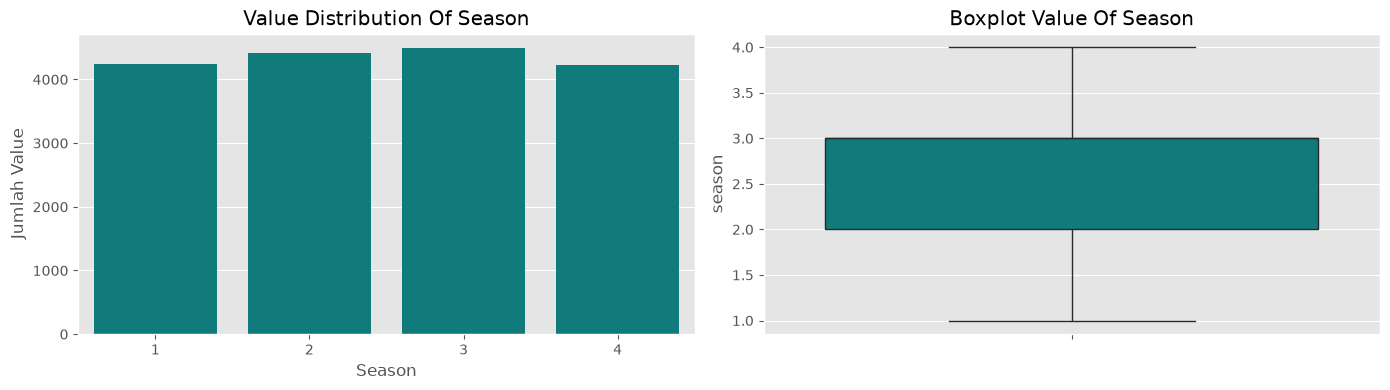

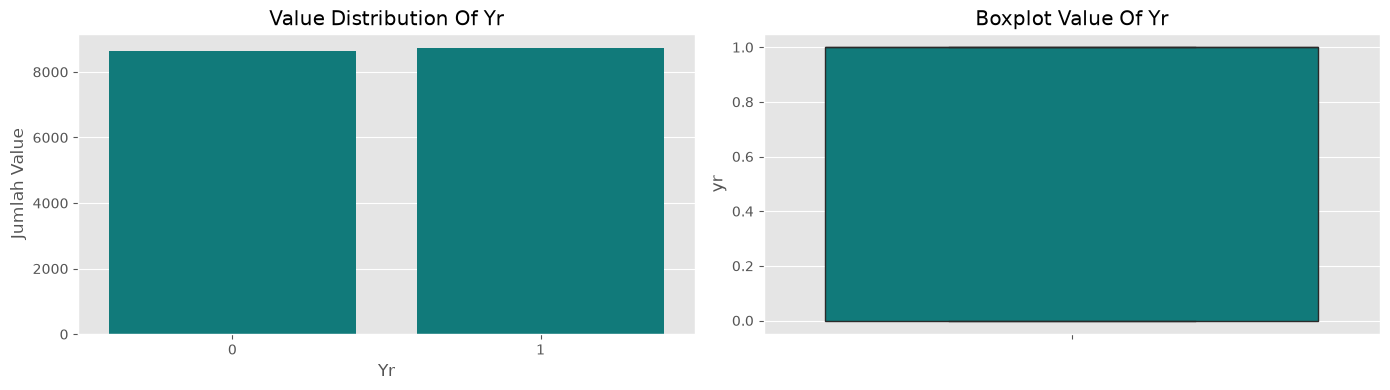

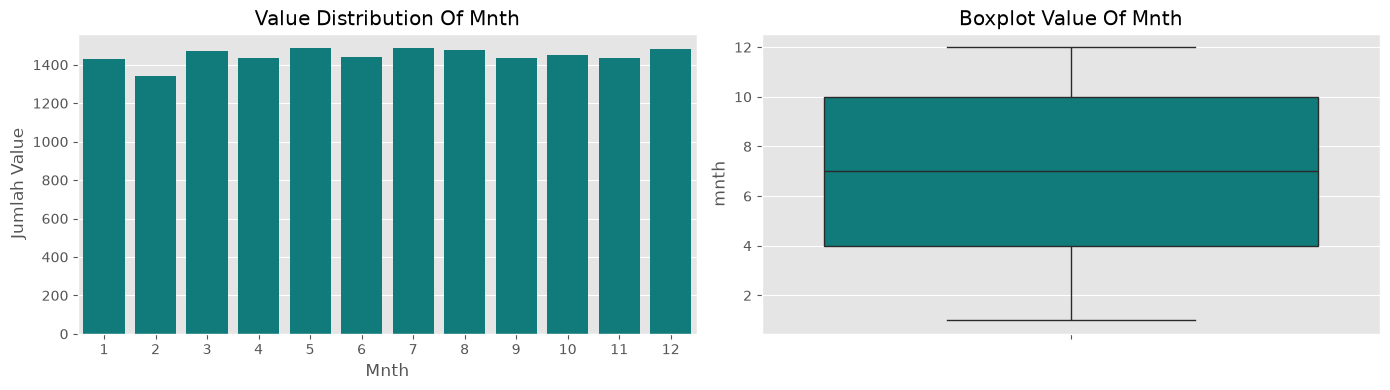

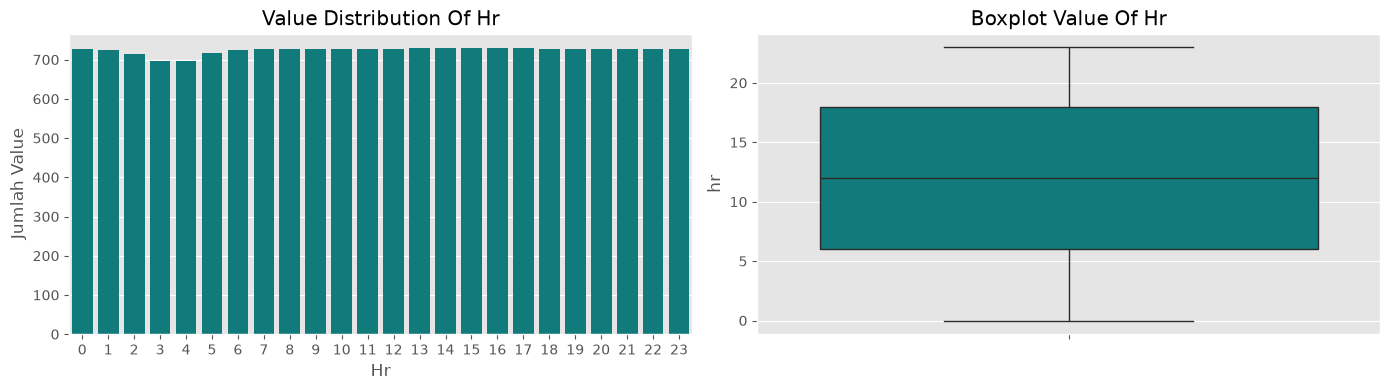

In [10]:
for col in ["season", "yr", "mnth", "hr"]:
    num_distribution(df_analyst,  col)

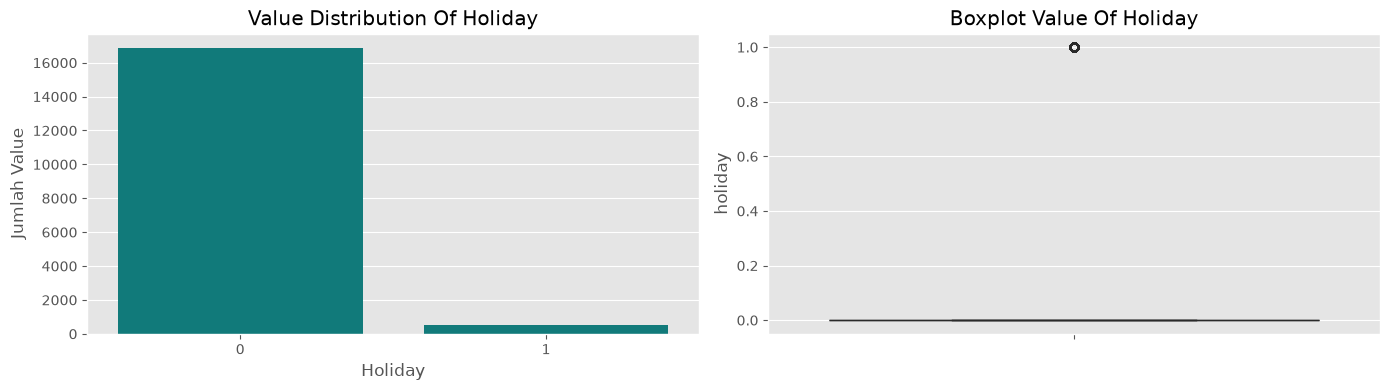

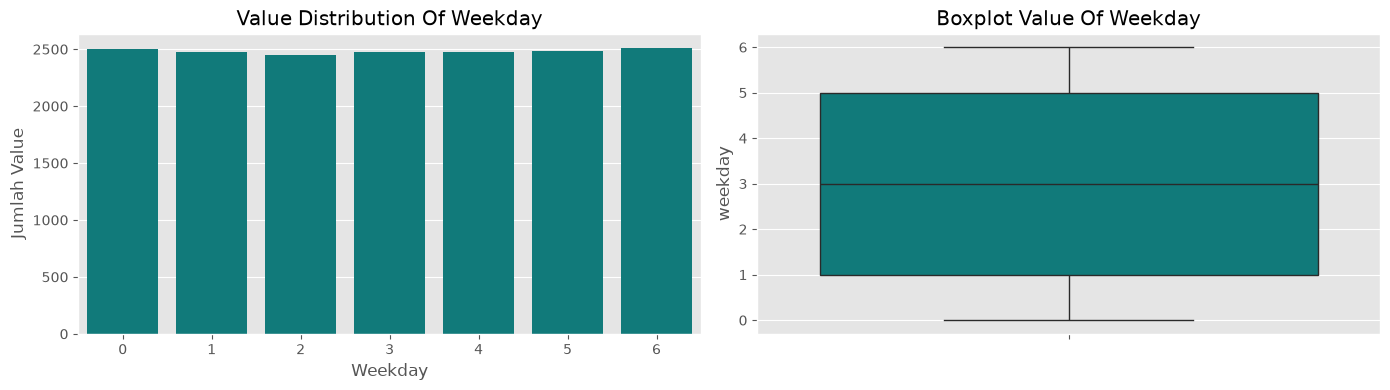

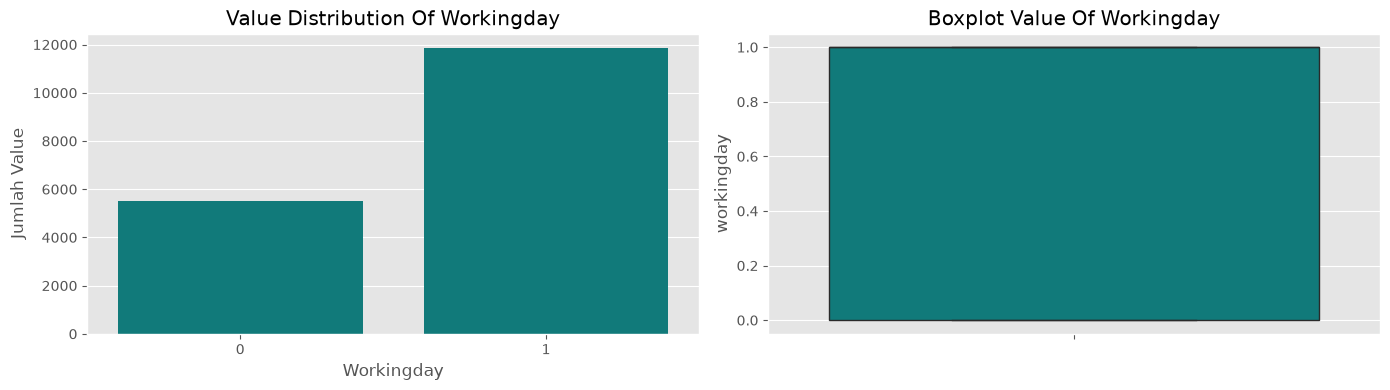

In [11]:
for col in ["holiday", "weekday", "workingday"]:
    num_distribution(df_analyst, col )

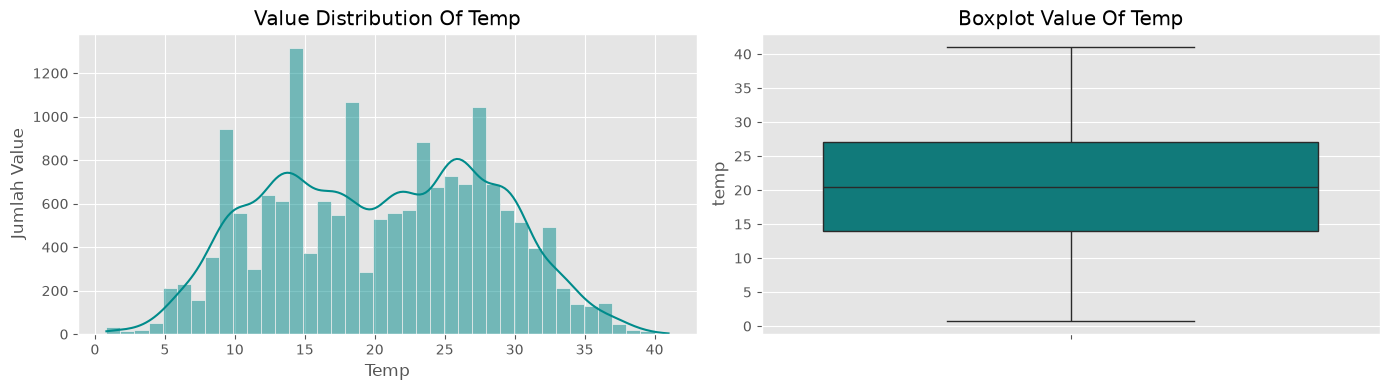

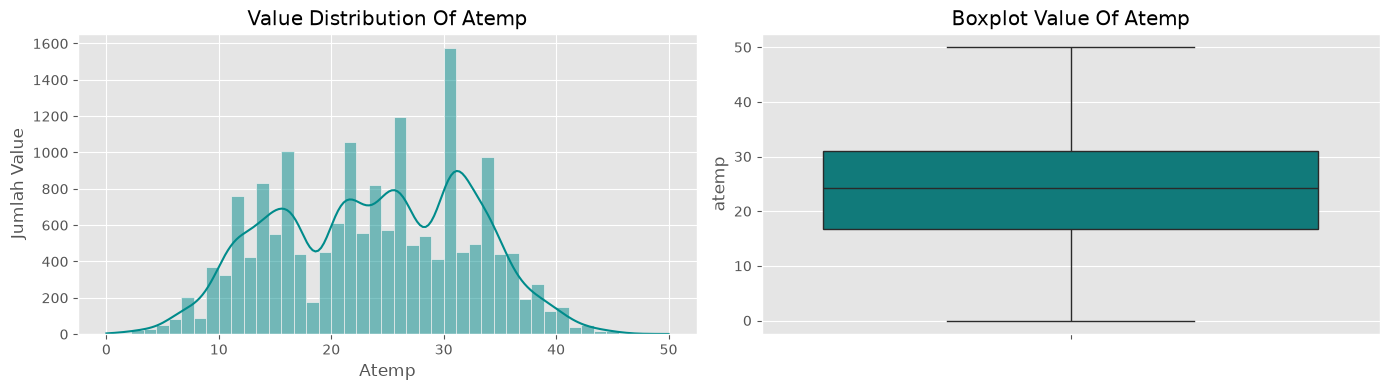

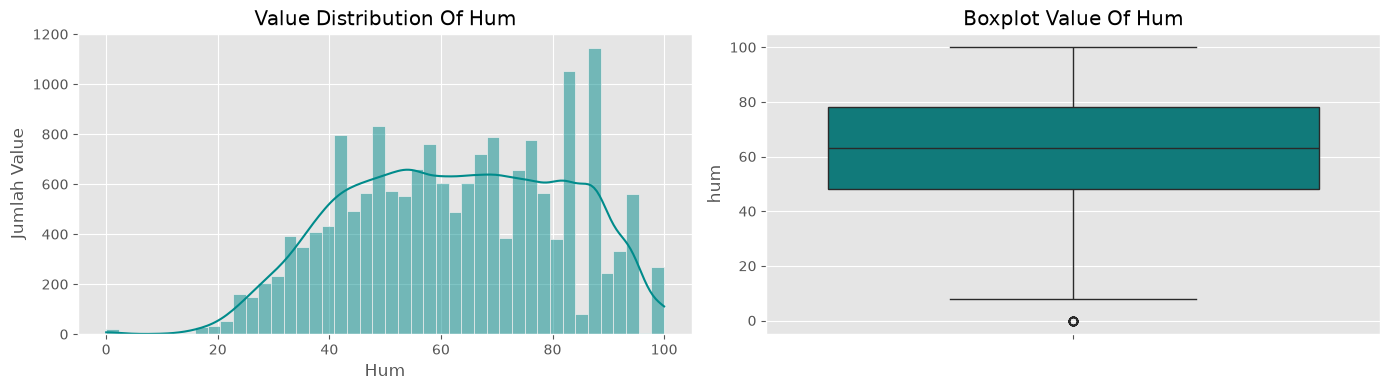

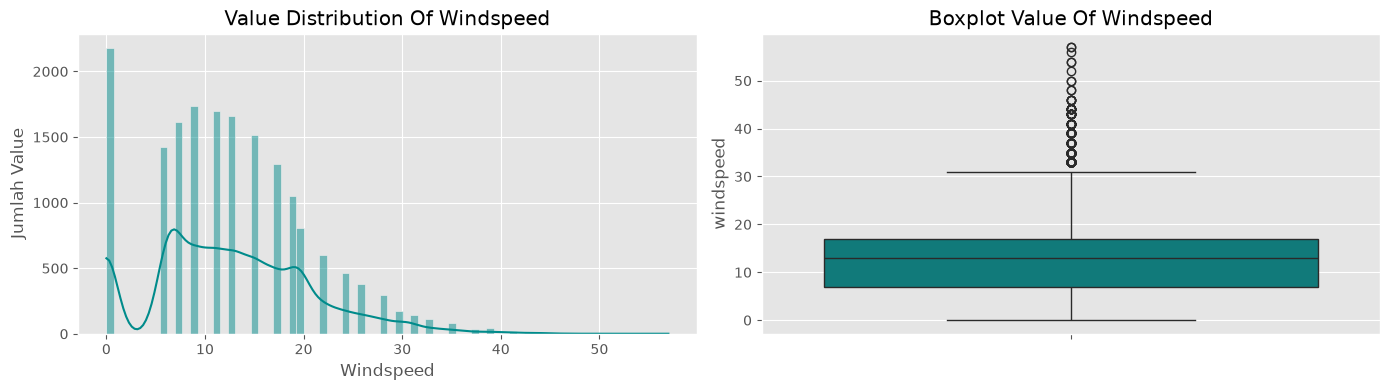

In [12]:
for col in ["temp", "atemp", "hum", "windspeed"]:
    num_distribution(df_analyst, col)

In [13]:
df_hum_check = df_analyst[df_analyst["hum"] == 0]

print(df_hum_check.shape)

df_hum_check.head()

(22, 16)


,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
1551,2011-03-10,1,0,3,0,0,4,1,3,13.94,15.910,0.0,16.9979,3,0,3
1552,2011-03-10,1,0,3,1,0,4,1,3,13.94,15.910,0.0,16.9979,0,2,2
1553,2011-03-10,1,0,3,2,0,4,1,3,13.94,15.910,0.0,16.9979,0,1,1
1554,2011-03-10,1,0,3,5,0,4,1,3,14.76,17.425,0.0,12.9980,1,2,3
1555,2011-03-10,1,0,3,6,0,4,1,3,14.76,16.665,0.0,22.0028,0,12,12


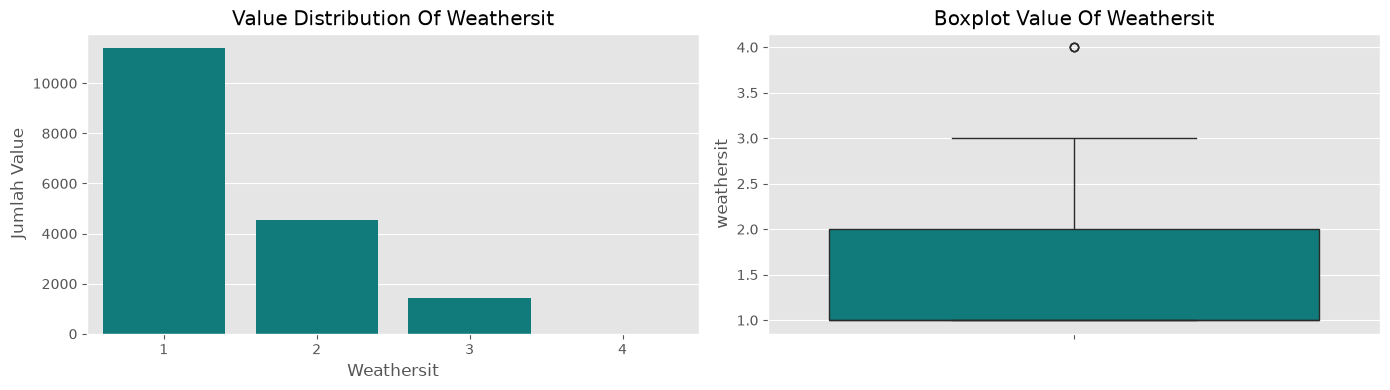

In [14]:
num_distribution(df_analyst, "weathersit")

In [15]:
# Memeriksa perbedan jumlah value pada weahtersit apakah NZV(near-zero variance) atau Sparse Category

wheathersit_count = pd.crosstab(
    index=df_analyst["weathersit"], columns="count", colnames=[""]
)
wheathersit_count["percentage"] = (
    round(pd.crosstab(
        index=df_analyst["weathersit"],
        columns="normalize",
        colnames=[""],
        normalize=True,
    ) * 100, 2)
)

display(wheathersit_count)

for i in range(1, 4):
    print(f"Ratio frequency dari {i+1} ke {1}: "
          f"{round(wheathersit_count["count"].iloc[0] / wheathersit_count["count"].iloc[i], 2)}")

,count,percentage
weathersit,,
1,11413,65.67
2,4544,26.15
3,1419,8.17
4,3,0.02


Ratio frequency dari 2 ke 1: 2.51
Ratio frequency dari 3 ke 1: 8.04
Ratio frequency dari 4 ke 1: 3804.33


In [16]:
# Menggabungkan weahtersit 4(hujan/salju lebat) ke 3(hujan/salju ringan) 

df.loc[df["weathersit"] == 4, "weathersit"] = 3

df["weathersit"].value_counts()

weathersit
1    11413
2     4544
3     1422
Name: count, dtype: int64

In [17]:
df.columns

Index(['dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='str')

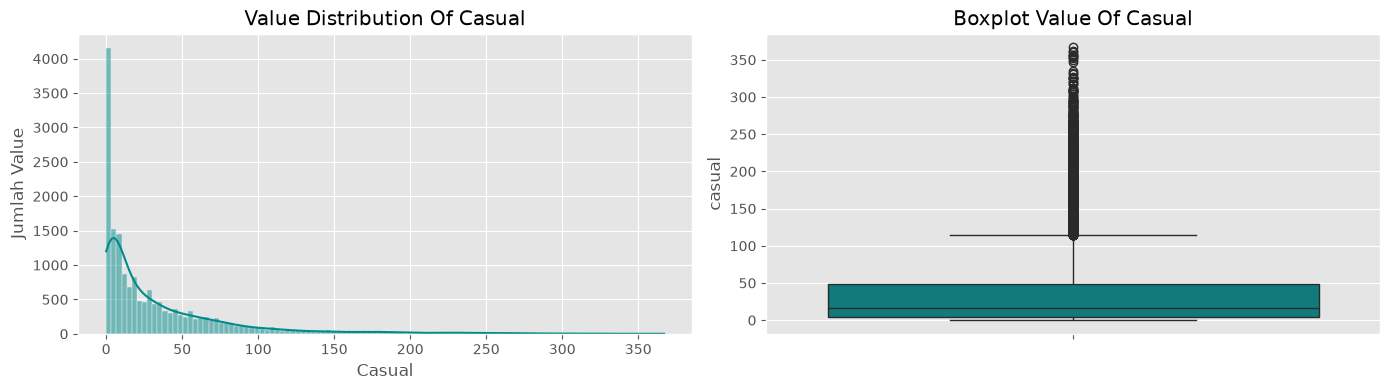

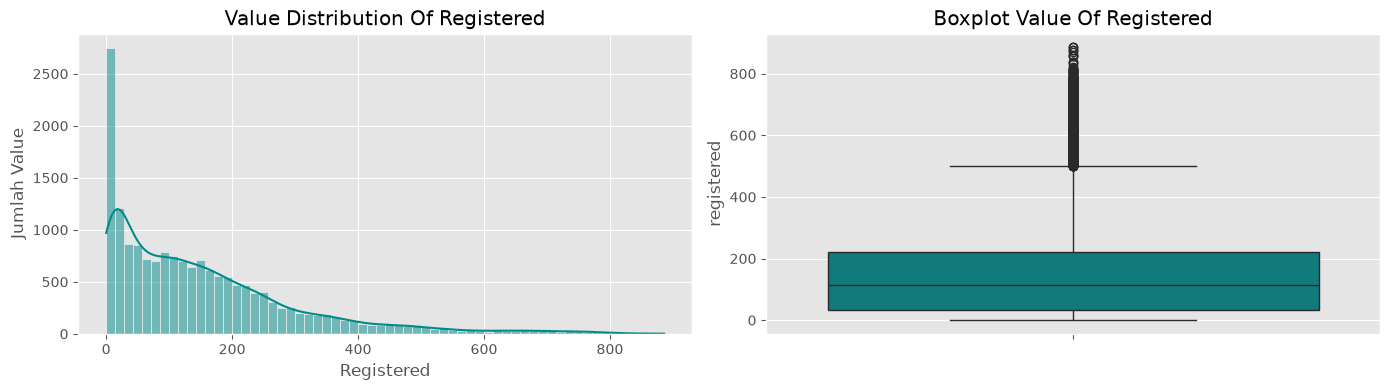

In [18]:
for col in ["casual", "registered"]:
    num_distribution(df, col)

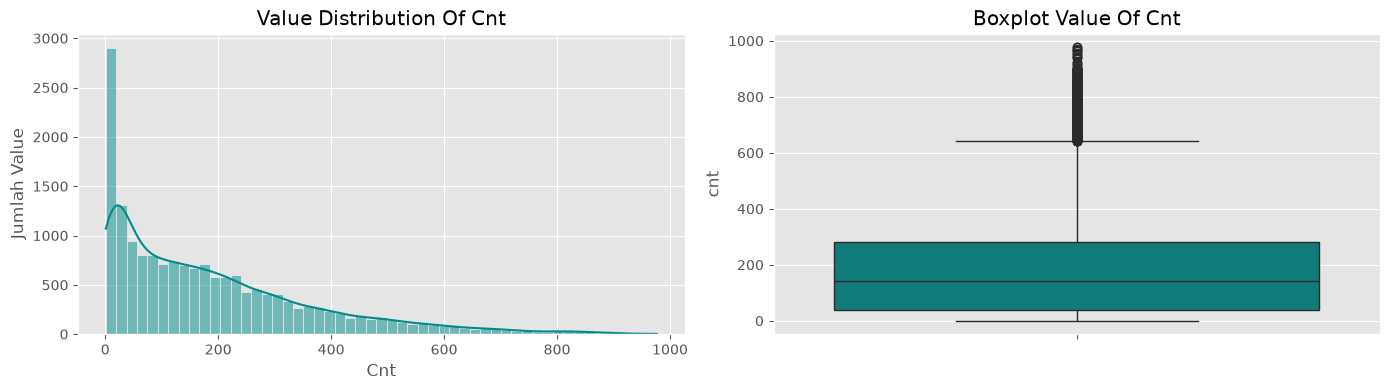

In [19]:
num_distribution(df, "cnt")

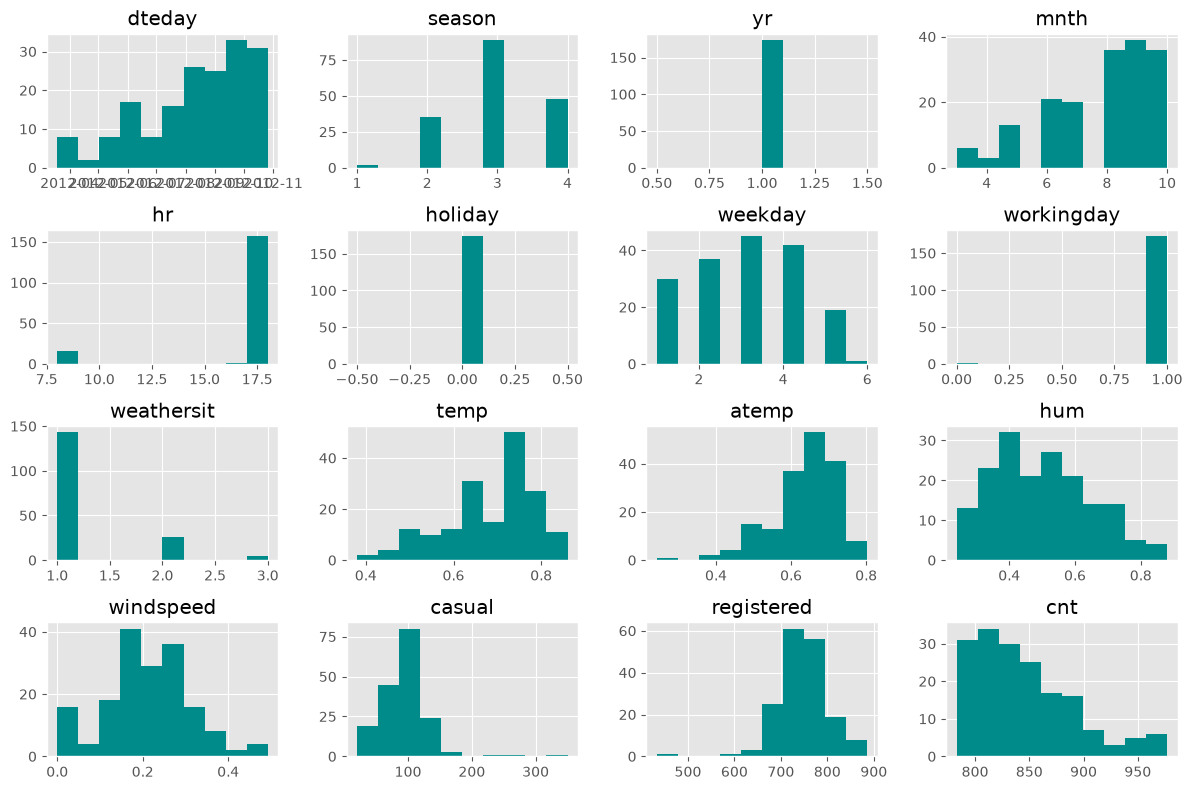

In [20]:
# Melihat karakteristik data pada data top 1% cnt

p99_cnt = df["cnt"].quantile(0.99)

df_cnt_filttered = df[df["cnt"] > p99_cnt]

df_cnt_filttered.hist(figsize= (12,8), color= "darkcyan")

plt.tight_layout( )
plt.show()

### Catatan Temuan & Pembersihan Data (Data Preprocessing)

1. **SPARSE CATEGORY PADA `WEATHERSIT`**
   * **Temuan:** Kategori `4` (Hujan/Salju Lebat) mengalami *sparse category* ekstrem yang hanya memiliki 3 sampel (0,02%) dari total 17.379 data, dengan perbandingan frekuensi yang sangat jauh dibandingkan kategori mayoritas (1 : 3.804).
   * **Penanganan:** Menggabungkan kategori `4` ke dalam kategori `3` (Hujan/Salju Ringan). Penggabungan ini dilakukan karena secara *domain knowledge* keduanya berada pada spektrum kondisi presipitasi (hujan/salju) yang sama, sekaligus membantu meningkatkan stabilitas model dengan membentuk kelompok data yang lebih seimbang (1.422 sampel / 8,19%) serta menekan risiko *overfitting*.

2. **ANOMALI VALUE `0` PADA `HUM` (KELEMBAPAN)**
   * **Temuan:** Terdapat nilai `0` pada kolom kelembapan udara (`hum`). Secara *domain knowledge* cuaca, kelembapan udara lingkungan outdoor bernilai mutlak 0% adalah kondisi yang sangat mustahil terjadi di alam nyata.
   * **Penanganan:** Membiarkan data tersebut (tidak melakukan *drop* atau *imputasi*) untuk tahap eksplorasi awal. Hal ini dilakukan karena jumlah baris yang terdampak sangat sedikit (22 baris) sehingga dampaknya diabaikan (*negligible*) terhadap distribusi keseluruhan, sekaligus untuk menghindari *bias* asumsi sebelum validasi lebih lanjut atau konfirmasi dari pihak *data provider*.

In [ ]:
# df.to_csv("hour_validated.csv", sep= ",", index= False)